# TRUSTSR Lab 09 — Trust-State Model and Transition Validation

**Status:** Synthetic simulation | State-machine prototype | Version 1.0.0

## Objective
Define and test five explicit trust states:
- **Trusted** — accepted as trusted by the current synthetic policy.
- **Recovered** — restored from a selected trusted snapshot, but not yet independently verified.
- **Unknown** — insufficient evidence to assign a stronger state.
- **Suspect** — evidence indicates a possible integrity or provenance problem, but contamination is not confirmed.
- **Contaminated** — the synthetic ground truth or a confirmed detection marks the state as compromised.

The states are labels in this lab, not proof that a real system is trustworthy. The notebook defines allowed transitions, rejects unsafe transitions, evaluates synthetic cases, and exports state/transition audit CSVs.

## Critical modeling rule
**Recovered is not automatically Trusted.** A recovered state must pass an independent verification step before it can transition to Trusted. Unknown and Suspect must not silently become Trusted merely because no alert is present. Contaminated must not transition directly to Trusted without recovery and verification.

## Evidence boundary
All examples and outcomes are synthetic. This lab validates the implemented state-machine rules; it does not establish that the signals, snapshots, or detection logic would be reliable in a real agent system.

## 1. Imports and state definitions

In [1]:
from enum import Enum
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

class TrustState(str, Enum):
    TRUSTED = "Trusted"
    RECOVERED = "Recovered"
    UNKNOWN = "Unknown"
    SUSPECT = "Suspect"
    CONTAMINATED = "Contaminated"

STATES = [s.value for s in TrustState]
print("States:", STATES)
print("Evidence classification: synthetic simulation")

States: ['Trusted', 'Recovered', 'Unknown', 'Suspect', 'Contaminated']
Evidence classification: synthetic simulation


## 2. Define the transition policy

In [2]:
# Explicitly permitted transitions. Any transition not listed here is rejected.
ALLOWED_TRANSITIONS = {
    "Trusted": {"Suspect", "Contaminated", "Unknown"},
    "Recovered": {"Trusted", "Suspect", "Contaminated", "Unknown"},
    "Unknown": {"Trusted", "Recovered", "Suspect", "Contaminated"},
    "Suspect": {"Recovered", "Contaminated", "Unknown"},
    "Contaminated": {"Recovered", "Unknown"},
}

def transition(current, target, *, verified=False, trusted_snapshot=False,
               compromise_confirmed=False, evidence_available=False):
    """Return (accepted, reason). This is a policy model, not a security oracle."""
    if current not in STATES or target not in STATES:
        return False, "invalid_state"
    if target not in ALLOWED_TRANSITIONS[current]:
        return False, "transition_not_allowed"
    if target == "Trusted":
        if current == "Recovered" and not verified:
            return False, "recovery_requires_independent_verification"
        if current == "Unknown" and not (verified and evidence_available):
            return False, "unknown_requires_evidence_and_verification"
        if current == "Recovered" and not trusted_snapshot:
            return False, "trusted_snapshot_required"
        if current == "Unknown" and not trusted_snapshot:
            return False, "trusted_snapshot_required"
    if target == "Contaminated" and not compromise_confirmed:
        return False, "confirmed_compromise_evidence_required"
    if target == "Recovered" and not trusted_snapshot:
        return False, "trusted_snapshot_required"
    if target == "Suspect" and not evidence_available:
        return False, "suspicion_evidence_required"
    return True, "accepted_by_synthetic_policy"

# Show the transition matrix for inspection.
matrix_rows = []
for source in STATES:
    row = {"from_state": source}
    for target in STATES:
        row[target] = target in ALLOWED_TRANSITIONS[source]
    matrix_rows.append(row)
transition_matrix_df = pd.DataFrame(matrix_rows)
display(transition_matrix_df)
print("Policy defined; disallowed transitions fail closed.")

     from_state  Trusted  Recovered  Unknown  Suspect  Contaminated
0       Trusted    False      False     True     True          True
1     Recovered     True      False     True     True          True
2       Unknown     True       True    False     True          True
3       Suspect    False       True     True    False          True
4  Contaminated    False       True     True    False         False

Policy defined; disallowed transitions fail closed.


## 3. Unit tests for critical safety rules

In [3]:
tests = []

def record_test(name, expected, actual, detail):
    passed = expected == actual
    tests.append({"test": name, "expected": expected, "actual": actual,
                  "passed": passed, "detail": detail})
    assert passed, f"{name}: expected {expected}, got {actual}"

# Recovery cannot imply trust without independent verification.
record_test("Recovered -> Trusted without verification", False,
            transition("Recovered", "Trusted", verified=False, trusted_snapshot=True)[0],
            "Must not auto-promote recovered state.")
record_test("Recovered -> Trusted after verification", True,
            transition("Recovered", "Trusted", verified=True, trusted_snapshot=True)[0],
            "Requires verification and trusted snapshot.")
record_test("Contaminated -> Trusted direct", False,
            transition("Contaminated", "Trusted", verified=True, trusted_snapshot=True)[0],
            "Direct transition is not allowed.")
record_test("Contaminated -> Recovered without snapshot", False,
            transition("Contaminated", "Recovered", trusted_snapshot=False)[0],
            "Recovery requires a trusted snapshot.")
record_test("Contaminated -> Recovered with snapshot", True,
            transition("Contaminated", "Recovered", trusted_snapshot=True)[0],
            "Recovery may start from a trusted snapshot.")
record_test("Suspect -> Contaminated without confirmation", False,
            transition("Suspect", "Contaminated", compromise_confirmed=False)[0],
            "Suspect is not the same as confirmed contamination.")
record_test("Suspect -> Contaminated with confirmation", True,
            transition("Suspect", "Contaminated", compromise_confirmed=True)[0],
            "Requires explicit confirmation.")
record_test("Unknown -> Trusted without evidence", False,
            transition("Unknown", "Trusted", verified=True, trusted_snapshot=True,
                       evidence_available=False)[0],
            "Absence of an alert is not evidence of trust.")
record_test("Unknown -> Trusted with evidence and verification", True,
            transition("Unknown", "Trusted", verified=True, trusted_snapshot=True,
                       evidence_available=True)[0],
            "Requires evidence, verification, and trusted snapshot.")
record_test("Trusted -> Contaminated direct state change without confirmation", False,
            transition("Trusted", "Contaminated", compromise_confirmed=False)[0],
            "Contamination requires confirming evidence.")

tests_df = pd.DataFrame(tests)
display(tests_df)
assert tests_df["passed"].all()
print(f"All {len(tests_df)} transition-policy unit tests passed.")

                                                               test  expected  actual  passed                                                  detail
0                         Recovered -> Trusted without verification     False   False    True                  Must not auto-promote recovered state.
1                           Recovered -> Trusted after verification      True    True    True             Requires verification and trusted snapshot.
2                                    Contaminated -> Trusted direct     False   False    True                       Direct transition is not allowed.
3                        Contaminated -> Recovered without snapshot     False   False    True                   Recovery requires a trusted snapshot.
4                           Contaminated -> Recovered with snapshot      True    True    True             Recovery may start from a trusted snapshot.
5                      Suspect -> Contaminated without confirmation     False   False    True     Su

All 10 transition-policy unit tests passed.


## 4. Simulate trust-state transitions

In [4]:
# Hand-authored synthetic scenarios. Expected outcomes are test fixtures, not empirical observations.
scenarios = [
    {"scenario":"S01","initial":"Trusted","target":"Suspect","verified":False,"snapshot":False,"confirmed":False,"evidence":True,
     "purpose":"An anomaly signal raises suspicion."},
    {"scenario":"S02","initial":"Suspect","target":"Contaminated","verified":False,"snapshot":False,"confirmed":True,"evidence":True,
     "purpose":"Independent evidence confirms compromise."},
    {"scenario":"S03","initial":"Contaminated","target":"Recovered","verified":False,"snapshot":True,"confirmed":False,"evidence":True,
     "purpose":"State is restored from a trusted snapshot."},
    {"scenario":"S04","initial":"Recovered","target":"Trusted","verified":False,"snapshot":True,"confirmed":False,"evidence":True,
     "purpose":"Attempt to trust before independent verification."},
    {"scenario":"S05","initial":"Recovered","target":"Trusted","verified":True,"snapshot":True,"confirmed":False,"evidence":True,
     "purpose":"Independent verification passes."},
    {"scenario":"S06","initial":"Unknown","target":"Trusted","verified":False,"snapshot":False,"confirmed":False,"evidence":False,
     "purpose":"No evidence is available."},
    {"scenario":"S07","initial":"Unknown","target":"Suspect","verified":False,"snapshot":False,"confirmed":False,"evidence":True,
     "purpose":"Incomplete evidence includes a warning signal."},
    {"scenario":"S08","initial":"Trusted","target":"Contaminated","verified":False,"snapshot":False,"confirmed":True,"evidence":True,
     "purpose":"Trusted state is invalidated after confirmed compromise."},
]
scenario_rows = []
for s in scenarios:
    accepted, reason = transition(
        s["initial"], s["target"], verified=s["verified"],
        trusted_snapshot=s["snapshot"], compromise_confirmed=s["confirmed"],
        evidence_available=s["evidence"]
    )
    scenario_rows.append({
        **s, "transition_accepted": accepted, "policy_reason": reason,
        "evidence_classification":"synthetic scenario"
    })
scenario_df = pd.DataFrame(scenario_rows)
display(scenario_df)
assert scenario_df.loc[scenario_df["scenario"]=="S04","transition_accepted"].iloc[0] == False
assert scenario_df.loc[scenario_df["scenario"]=="S05","transition_accepted"].iloc[0] == True
assert scenario_df.loc[scenario_df["scenario"]=="S06","transition_accepted"].iloc[0] == False
print("Scenario assertions passed.")

  scenario       initial        target  verified  snapshot  confirmed  evidence                                                   purpose  transition_accepted  \
0      S01       Trusted       Suspect     False     False      False      True                       An anomaly signal raises suspicion.                 True   
1      S02       Suspect  Contaminated     False     False       True      True                 Independent evidence confirms compromise.                 True   
2      S03  Contaminated     Recovered     False      True      False      True                State is restored from a trusted snapshot.                 True   
3      S04     Recovered       Trusted     False      True      False      True         Attempt to trust before independent verification.                False   
4      S05     Recovered       Trusted      True      True      False      True                          Independent verification passes.                 True   
5      S06       Unknown    

Scenario assertions passed.


## 5. Synthetic state-count and rejected-transition summaries

    trust_state  count
0       Trusted      5
1     Recovered      3
2       Unknown      2
3       Suspect      3
4  Contaminated      3

        initial        target  transition_accepted  scenario_count
0  Contaminated     Recovered                 True               1
1     Recovered       Trusted                False               1
2     Recovered       Trusted                 True               1
3       Suspect  Contaminated                 True               1
4       Trusted  Contaminated                 True               1
5       Trusted       Suspect                 True               1
6       Unknown       Suspect                 True               1
7       Unknown       Trusted                False               1

Do not interpret these counts as real-world state prevalence or security effectiveness.


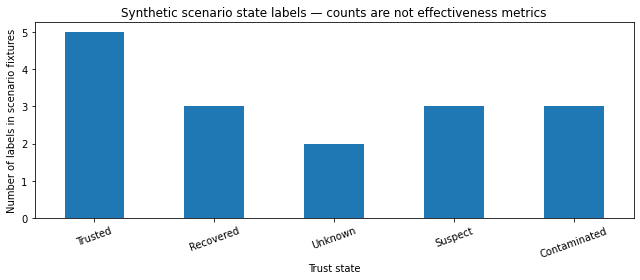

In [5]:
state_counts = pd.Series(
    [s["initial"] for s in scenarios] + [s["target"] for s in scenarios],
    name="state"
).value_counts().reindex(STATES, fill_value=0).rename_axis("trust_state").reset_index(name="count")
display(state_counts)

ax = state_counts.plot(kind="bar", x="trust_state", y="count", legend=False, figsize=(9,4))
ax.set_title("Synthetic scenario state labels — counts are not effectiveness metrics")
ax.set_xlabel("Trust state")
ax.set_ylabel("Number of labels in scenario fixtures")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

transition_summary = scenario_df.groupby(["initial","target","transition_accepted"]).size().reset_index(name="scenario_count")
display(transition_summary)
print("Do not interpret these counts as real-world state prevalence or security effectiveness.")

## 6. Export CSVs

In [6]:
transition_matrix_df.to_csv("trustsr_lab09_transition_matrix.csv", index=False)
tests_df.to_csv("trustsr_lab09_transition_unit_tests.csv", index=False)
scenario_df.to_csv("trustsr_lab09_synthetic_scenarios.csv", index=False)
state_counts.to_csv("trustsr_lab09_synthetic_state_counts.csv", index=False)
transition_summary.to_csv("trustsr_lab09_transition_summary.csv", index=False)

for filename in [
    "trustsr_lab09_transition_matrix.csv",
    "trustsr_lab09_transition_unit_tests.csv",
    "trustsr_lab09_synthetic_scenarios.csv",
    "trustsr_lab09_synthetic_state_counts.csv",
    "trustsr_lab09_transition_summary.csv"
]:
    p = Path(filename)
    assert p.exists() and p.stat().st_size > 0
    print("Created:", filename, "| bytes:", p.stat().st_size)

assert tests_df["passed"].all()
assert scenario_df["evidence_classification"].eq("synthetic scenario").all()
print("Evidence classification: synthetic state-machine simulation only.")

Created: trustsr_lab09_transition_matrix.csv | bytes: 239
Created: trustsr_lab09_transition_unit_tests.csv | bytes: 1061
Created: trustsr_lab09_synthetic_scenarios.csv | bytes: 1275
Created: trustsr_lab09_synthetic_state_counts.csv | bytes: 75
Created: trustsr_lab09_transition_summary.csv | bytes: 257
Evidence classification: synthetic state-machine simulation only.


## 7. Interpretation limits and publication wording

### What this lab supports
- A concrete five-state trust vocabulary for the prototype.
- An explicit allow-list of state transitions and fail-closed rejection of unlisted transitions.
- Unit tests for the policy rules, including the rule that Recovered is not automatically Trusted.
- Reproducible synthetic scenario tables and CSV exports.

### What this lab does not support
- That these five states are sufficient for every agent architecture.
- That the chosen transition policy is optimal, formally verified, or secure against adversarial manipulation.
- That evidence signals, snapshots, or independent verification are reliable in a real system.
- Any empirical claim about real-world agent contamination or recovery.

### Publication wording
“We implemented a five-state trust-state machine and evaluated its specified transition rules against hand-authored synthetic scenarios. Unit tests verified selected policy constraints, including separation of recovery from trust promotion. The results validate implementation behavior against the stated policy only; they do not establish real-world security effectiveness.”

### Before citing this lab
1. Run all cells in a fresh Colab runtime.
2. Confirm all assertions pass and all five CSV exports are created.
3. Review whether every allowed transition has a documented rationale in the monograph.
4. Treat the transition matrix as a proposed policy requiring future threat-model review, not as a proven universal model.